## Analyze Monthly Mean Temperature Variations at Two Meteorological Stations

### 1. Identify Missing Data
Check the dataset for missing temperature values and determine which observations are incomplete.

### 2. Handle Missing Data
Remove observations with missing temperature values to ensure that the monthly averages are calculated from valid data.

### 3. Calculate and Visualize Monthly Mean Temperatures
Calculate the monthly mean temperature for each station and plot both temperature series on the same graph to compare their seasonal variations.

In [2]:
# Import librarie
import ast
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import calendar

In [3]:


# Charger les données
df = pd.read_csv('Temp_moy_obs.csv', sep=';')
df['Date'] = pd.to_datetime(df['Date'])

# Extraire année et mois
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['month_name'] = pd.to_datetime(df['Date']).dt.strftime('%b')

# Compter le nombre de jours observés par (année, mois)
days_count = df.groupby(['year','month']).size().reset_index(name='observed_days')

# Ajouter le nombre de jours attendus
days_count['expected_days'] = days_count.apply(
    lambda row: calendar.monthrange(row['year'], row['month'])[1], axis=1
)

# Identifier les mois incomplets
incomplete_months = days_count[days_count['observed_days'] != days_count['expected_days']]
print("Mois incomplets détectés :")
print(incomplete_months)


Mois incomplets détectés :
Empty DataFrame
Columns: [year, month, observed_days, expected_days]
Index: []


In [4]:
days_count

,year,month,observed_days,expected_days
0,1993,1,31,31
1,1993,2,28,28
2,1993,3,31,31
3,1993,4,30,30
4,1993,5,31,31
...,...,...,...,...
367,2023,8,31,31
368,2023,9,30,30
369,2023,10,31,31
370,2023,11,30,30


In [5]:
# Supprimer toutes les lignes avec valeurs manquantes
df_clean = df.dropna(subset=['PARAKOU', 'NATITINGOU'])
df_clean

,Date,NATITINGOU,Unnamed: 2,PARAKOU,year,month,month_name
0,1993-01-01,29.40,NaN,27.80,1993,1,Jan
1,1993-01-02,29.35,NaN,28.00,1993,1,Jan
2,1993-01-03,28.40,NaN,28.20,1993,1,Jan
3,1993-01-04,27.45,NaN,28.60,1993,1,Jan
4,1993-01-05,22.45,NaN,23.15,1993,1,Jan
...,...,...,...,...,...,...,...
11317,2023-12-27,22.90,NaN,27.10,2023,12,Dec
11318,2023-12-28,23.70,NaN,27.70,2023,12,Dec
11319,2023-12-29,24.40,NaN,28.00,2023,12,Dec
11320,2023-12-30,24.30,NaN,28.20,2023,12,Dec


In [6]:

monthly_means = df_clean.groupby(['month_name'])[['PARAKOU','NATITINGOU']].mean().reset_index()

# Définir l'ordre des mois
month_order = ["Jan","Feb","Mar","Apr","May","Jun",
               "Jul","Aug","Sep","Oct","Nov","Dec"]

# Transformer la colonne en type catégoriel avec ordre
monthly_means['month_name'] = pd.Categorical(
    monthly_means['month_name'], 
    categories=month_order, 
    ordered=True
)

# Trier selon l'ordre défini
monthly_means = monthly_means.sort_values('month_name')

monthly_means

,month_name,PARAKOU,NATITINGOU
4,Jan,27.523465,26.494901
3,Feb,29.616457,28.709029
7,Mar,30.712539,30.766753
0,Apr,29.733763,30.342688
8,May,28.247971,28.718314
6,Jun,26.723065,27.000000
5,Jul,25.806348,25.813736
1,Aug,25.234599,25.360458
11,Sep,25.714624,25.912742
10,Oct,26.858741,26.970187


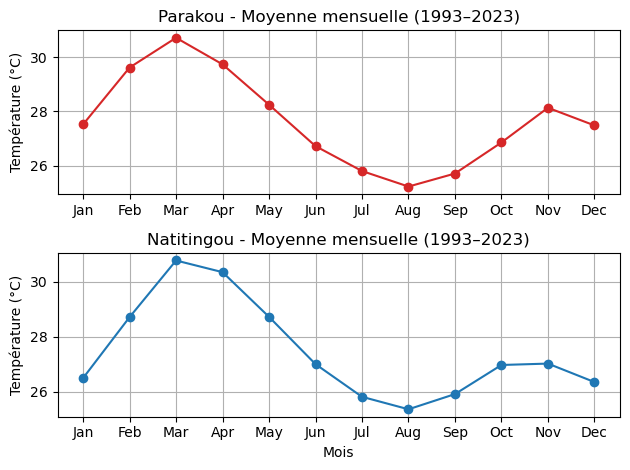

In [15]:
# Créer deux sous-plots (2 lignes, 1 colonne)
fig, ax = plt.subplots(2, 1)

# Premier subplot : Parakou
ax[0].plot(monthly_means['month_name'], monthly_means['PARAKOU'], marker='o', color='tab:red')
ax[0].set_title('Parakou - Moyenne mensuelle (1993–2023)')
ax[0].set_ylabel('Température (°C)')
ax[0].grid(True)

# Deuxième subplot : Natitingou
ax[1].plot(monthly_means['month_name'], monthly_means['NATITINGOU'], marker='o', color='tab:blue')
ax[1].set_title('Natitingou - Moyenne mensuelle (1993–2023)')
ax[1].set_xlabel('Mois')
ax[1].set_ylabel('Température (°C)')
ax[1].grid(True)

plt.tight_layout()
plt.show()

In [16]:
# Transformer en format long pour Seaborn
monthly_long = monthly_means.reset_index().melt(id_vars='month_name',
                                                value_vars=['PARAKOU','NATITINGOU'],
                                                var_name='Station',
                                                value_name='Température')
monthly_long.rename(columns={'month_name':'Mois'}, inplace=True)
monthly_long['Mois'] = pd.Categorical(monthly_long['Mois'], categories=month_order, ordered=True)

monthly_long

,Mois,Station,Température
0,Jan,PARAKOU,27.523465
1,Feb,PARAKOU,29.616457
2,Mar,PARAKOU,30.712539
3,Apr,PARAKOU,29.733763
4,May,PARAKOU,28.247971
5,Jun,PARAKOU,26.723065
6,Jul,PARAKOU,25.806348
7,Aug,PARAKOU,25.234599
8,Sep,PARAKOU,25.714624
9,Oct,PARAKOU,26.858741


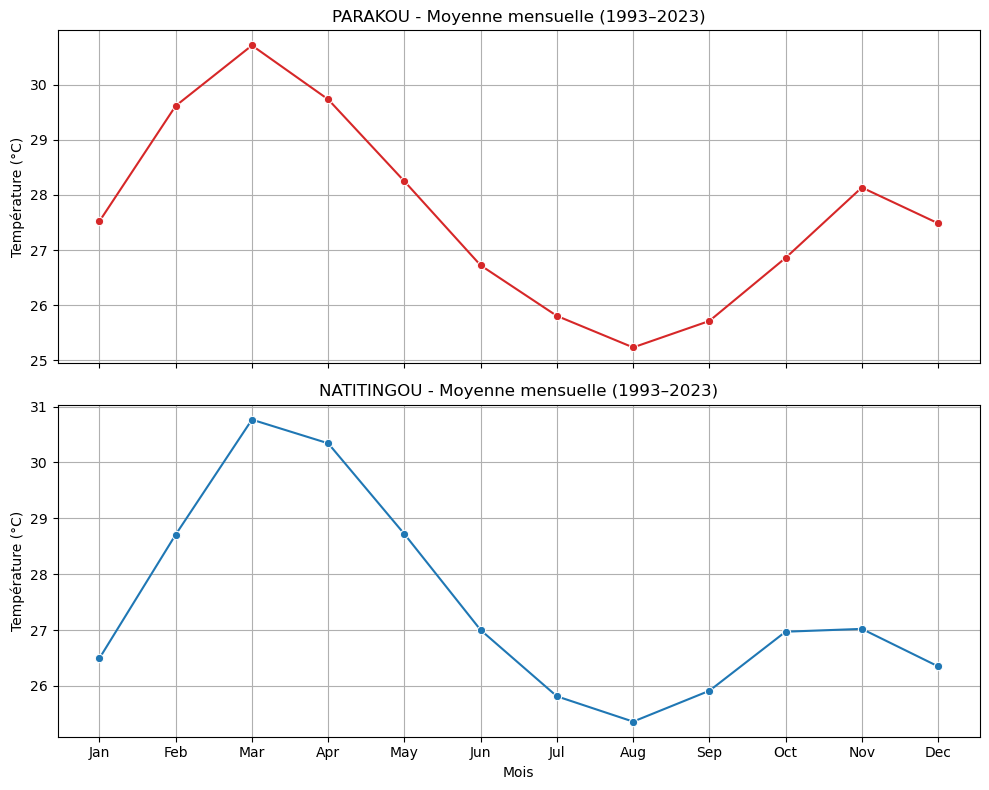

In [19]:
# Créer deux sous-plots
fig, ax = plt.subplots(2, 1, figsize=(10,8), sharex=True)

# Boucle pour tracer chaque station
stations = ['PARAKOU','NATITINGOU']
colors = ['tab:red','tab:blue']

for i, station in enumerate(stations):
    sns.lineplot(data=monthly_long[monthly_long['Station']==station],
                 x='Mois', y='Température', marker='o',
                 ax=ax[i], color=colors[i])
    ax[i].set_title(f'{station} - Moyenne mensuelle (1993–2023)')
    ax[i].set_ylabel('Température (°C)')
    ax[i].grid(True)

# Ajouter l’axe des mois en bas
ax[-1].set_xlabel('Mois')

plt.tight_layout()
plt.show()